In [1]:
# Import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

print("Library berhasil diimport!")

Library berhasil diimport!


In [4]:
# Load dataset terlebih dahulu
df = pd.read_csv('/content/Customer-Churn-Records.csv')

# Melihat jumlah baris dan kolom
print("Ukuran Dataset:", df.shape)

# Melihat nama kolom
print("\nNama Kolom:")
print(df.columns)

# Melihat informasi dataset
df.info()

# Melihat statistik deskriptif
df.describe()

Ukuran Dataset: (10000, 10)

Nama Kolom:
Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   RowNumber      10000 non-null  int64  
 1   CustomerId     10000 non-null  int64  
 2   Surname        10000 non-null  object 
 3   CreditScore    10000 non-null  int64  
 4   Geography      10000 non-null  object 
 5   Gender         10000 non-null  object 
 6   Age            10000 non-null  int64  
 7   Tenure         10000 non-null  int64  
 8   Balance        10000 non-null  float64
 9   NumOfProducts  10000 non-null  int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 781.4+ KB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000


In [5]:
# Mengambil 100 sampel secara acak

sampel = df['Balance'].sample(
    n=100,
    random_state=42
)

# Mengubah menjadi array
data = sampel.values

# Menampilkan data sampel
print("100 Data Sampel:")
print(data)

print("\nJumlah Sampel:", len(data))

100 Data Sampel:
[ 96709.07      0.        0.   119152.1  124995.98      0.   138901.61
 101528.61 113794.22  85679.25      0.        0.        0.   154007.21
 110928.51 119799.27      0.   166776.6       0.        0.   101891.1
      0.        0.    88141.1       0.   204510.94 147487.23 148874.01
      0.   134320.23 141441.75      0.   103821.47      0.   146679.77
  99340.83 105489.31      0.   128718.78      0.   148045.68 134264.04
      0.        0.   106036.52  70349.48 100446.57  69014.49 110641.18
 147936.42  88120.97 152462.79  92436.86 110067.71  89158.94      0.
 101440.36  55776.39      0.    47869.69 128262.72      0.   133200.09
  99806.85 100912.19 162390.52      0.   153545.11 106396.48 147285.52
 179305.09 133636.16 174701.05      0.   111589.33 127476.73      0.
 125903.22      0.    57809.32      0.   111577.01 117691.   139859.23
  92347.96  69329.47      0.   114959.12 124179.3  125689.29  85615.66
      0.        0.        0.        0.   135096.05 144272.07 1047

In [6]:
# Menghitung estimasi titik dan interval

n = len(data)

# Estimasi titik
rata_rata = np.mean(data)

# Standar deviasi
std = np.std(data, ddof=1)

# Tingkat kesalahan 5%
alpha = 0.05

# Nilai Z
z = stats.norm.ppf(1 - alpha/2)

# Standard error
se = std / np.sqrt(n)

# Batas interval
batas_bawah = rata_rata - z * se
batas_atas = rata_rata + z * se

# Menampilkan hasil
print("HASIL ESTIMASI TITIK DAN INTERVAL")
print("--------------------------------")
print("Jumlah Sampel:", n)
print("Rata-rata Sampel:", rata_rata)
print("Standar Deviasi:", std)
print("Nilai Z:", z)
print("Standard Error:", se)

print("\nEstimasi Interval 95%")
print("Batas Bawah:", batas_bawah)
print("Batas Atas:", batas_atas)

HASIL ESTIMASI TITIK DAN INTERVAL
--------------------------------
Jumlah Sampel: 100
Rata-rata Sampel: 80744.96720000001
Standar Deviasi: 60984.3208712462
Nilai Z: 1.959963984540054
Standard Error: 6098.43208712462

Estimasi Interval 95%
Batas Bawah: 68792.25994707232
Batas Atas: 92697.6744529277


In [7]:
# RESAMPLING METODE JACKKNIFE

jackknife_results = []

for i in range(n):

    # Menghapus satu data
    data_jackknife = np.delete(data, i)

    # Menghitung rata-rata
    mean_jackknife = np.mean(data_jackknife)

    jackknife_results.append(mean_jackknife)

# Menghitung rata-rata hasil Jackknife
rata_jackknife = np.mean(jackknife_results)

# Menghitung standar error Jackknife
jackknife_se = np.sqrt(
    (n - 1) / n *
    np.sum((jackknife_results - rata_jackknife)**2)
)

print("HASIL JACKKNIFE")
print("-------------------------")
print("Jumlah Resampling:", len(jackknife_results))
print("Rata-rata Jackknife:", rata_jackknife)
print("Standar Error Jackknife:", jackknife_se)

HASIL JACKKNIFE
-------------------------
Jumlah Resampling: 100
Rata-rata Jackknife: 80744.96719999998
Standar Error Jackknife: 6098.432087124643


In [8]:
# RESAMPLING METODE BOOTSTRAPPING

bootstrap_results = []

np.random.seed(42)

for i in range(1000):

    # Mengambil sampel dengan pengembalian
    data_bootstrap = np.random.choice(
        data,
        size=n,
        replace=True
    )

    # Menghitung rata-rata
    mean_bootstrap = np.mean(data_bootstrap)

    bootstrap_results.append(mean_bootstrap)

# Menghitung rata-rata hasil bootstrap
rata_bootstrap = np.mean(bootstrap_results)

# Menghitung standar deviasi bootstrap
std_bootstrap = np.std(bootstrap_results, ddof=1)

print("HASIL BOOTSTRAPPING")
print("-------------------------")
print("Jumlah Iterasi:", len(bootstrap_results))
print("Rata-rata Bootstrap:", rata_bootstrap)
print("Standar Deviasi Bootstrap:", std_bootstrap)

HASIL BOOTSTRAPPING
-------------------------
Jumlah Iterasi: 1000
Rata-rata Bootstrap: 80383.17276969999
Standar Deviasi Bootstrap: 6256.377493236768


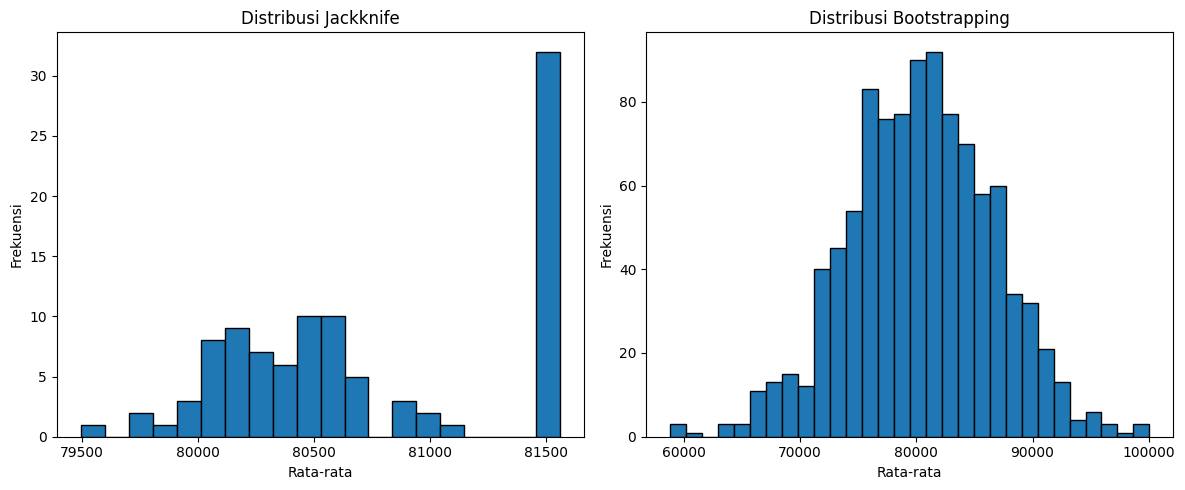

In [9]:
# Membuat grafik hasil resampling

plt.figure(figsize=(12, 5))

# Grafik Jackknife
plt.subplot(1, 2, 1)
plt.hist(jackknife_results, bins=20, edgecolor='black')
plt.title('Distribusi Jackknife')
plt.xlabel('Rata-rata')
plt.ylabel('Frekuensi')

# Grafik Bootstrap
plt.subplot(1, 2, 2)
plt.hist(bootstrap_results, bins=30, edgecolor='black')
plt.title('Distribusi Bootstrapping')
plt.xlabel('Rata-rata')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [10]:
# Membuat tabel perbandingan

hasil = pd.DataFrame({
    'Metode': [
        'Estimasi Titik',
        'Jackknife',
        'Bootstrapping'
    ],

    'Rata-rata': [
        rata_rata,
        rata_jackknife,
        rata_bootstrap
    ]
})

print("TABEL PERBANDINGAN HASIL")
print(hasil)

TABEL PERBANDINGAN HASIL
           Metode    Rata-rata
0  Estimasi Titik  80744.96720
1       Jackknife  80744.96720
2   Bootstrapping  80383.17277
